## Imports Required Libraries

In [1]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd

import random
import math
import time
import os

import matplotlib.pyplot as plt

import pulp

## Generate Synthetic Dataset

In [2]:
# ============================================
# 2. SYNTHETIC DATASET GENERATION
# ============================================

np.random.seed(42)

n_customers = 20

customers = pd.DataFrame({
    "customer_id": range(1, n_customers + 1),
    "x": np.random.uniform(0, 100, n_customers),
    "y": np.random.uniform(0, 100, n_customers),
    "demand": np.random.randint(1, 10, n_customers)
})

# Depot
depot = {
    "customer_id": 0,
    "x": 50,
    "y": 50,
    "demand": 0
}

print("Synthetic Dataset")
print("=================")
print(customers)

print("\nDepot:")
print(depot)

Synthetic Dataset
    customer_id          x          y  demand
0             1  37.454012  61.185289       7
1             2  95.071431  13.949386       8
2             3  73.199394  29.214465       3
3             4  59.865848  36.636184       1
4             5  15.601864  45.606998       4
5             6  15.599452  78.517596       2
6             7   5.808361  19.967378       8
7             8  86.617615  51.423444       4
8             9  60.111501  59.241457       2
9            10  70.807258   4.645041       6
10           11   2.058449  60.754485       6
11           12  96.990985  17.052412       4
12           13  83.244264   6.505159       6
13           14  21.233911  94.888554       2
14           15  18.182497  96.563203       2
15           16  18.340451  80.839735       4
16           17  30.424224  30.461377       8
17           18  52.475643   9.767211       7
18           19  43.194502  68.423303       9
19           20  29.122914  44.015249       8

Depot:
{'custom

## Dataset Justification

The dataset is synthetic, generated to represent a small delivery company that serves customers from a single warehouse.

| Element | Value | Real-world meaning |
|---|---|---|
| Service area | 0–100 on each axis | A 100 km × 100 km region around a city |
| Depot | (50, 50) | Central warehouse where every vehicle starts and ends its route |
| Customers | 20, placed uniformly at random | Delivery addresses spread across the region |
| Demand | 1–9 units per customer | Parcels or crates per delivery |
| Fleet | 4 vehicles, capacity 30 each | Small courier vans |

**Realism.** Total demand is 101 units against a total fleet capacity of 120 units (84% utilisation). The fleet can serve every customer, but only with little spare room, so the capacity constraint actively shapes the routes, as it does in real delivery planning. Distances are Euclidean, a standard approximation of road distance in vehicle routing studies.

**Why synthetic data.** The same generator can create instances of any size, which is needed for the scalability experiment (10 to 100 customers). The problem size can then be changed while everything else stays the same.

**Reproducibility.** A fixed random seed (42) means anyone running the notebook obtains exactly the same customers, demands and results.

## Dataset Generation Function

In [3]:
# ============================================
# 3. DATASET GENERATION FUNCTION
# ============================================

def generate_dataset(n_customers, seed=42):

    np.random.seed(seed)

    data = pd.DataFrame({
        "customer_id": range(1, n_customers + 1),
        "x": np.random.uniform(0, 100, n_customers),
        "y": np.random.uniform(0, 100, n_customers),
        "demand": np.random.randint(1, 10, n_customers)
    })

    return data


# Generate default dataset
customers = generate_dataset(20, seed=42)

customers.head()

,customer_id,x,y,demand
0,1,37.454012,61.185289,7
1,2,95.071431,13.949386,8
2,3,73.199394,29.214465,3
3,4,59.865848,36.636184,1
4,5,15.601864,45.606998,4


## Vehicle Configuration

In [4]:
# ============================================
# 4. VEHICLE CONFIGURATION
# ============================================

NUM_VEHICLES = 4
VEHICLE_CAPACITY = 30

print("Number of vehicles:", NUM_VEHICLES)
print("Vehicle capacity:", VEHICLE_CAPACITY)

Number of vehicles: 4
Vehicle capacity: 30


## Feasibility Check

In [5]:
# ============================================
# 5. FEASIBILITY CHECK
# ============================================

total_demand = customers["demand"].sum()
total_capacity = NUM_VEHICLES * VEHICLE_CAPACITY

print("Total demand:", total_demand)
print("Total vehicle capacity:", total_capacity)

if total_demand <= total_capacity:
    print("Problem is feasible.")
else:
    print("Problem is infeasible.")

Total demand: 101
Total vehicle capacity: 120
Problem is feasible.


## Distance Matrix

In [6]:
# ============================================
# 6. DISTANCE MATRIX
# ============================================

def calculate_distance_matrix(
    customers,
    depot_x=50,
    depot_y=50,
    rounded=False
):
    
    locations = [
        (depot_x, depot_y)
    ] + list(
        zip(customers["x"], customers["y"])
    )

    n = len(locations)

    distance_matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):

            x1, y1 = locations[i]
            x2, y2 = locations[j]

            distance = np.sqrt(
                (x1 - x2) ** 2 +
                (y1 - y2) ** 2
            )

            if rounded:
                distance = int(distance + 0.5)

            distance_matrix[i][j] = distance

    return distance_matrix


distance_matrix = calculate_distance_matrix(
    customers
)

print("Distance matrix shape:", distance_matrix.shape)

Distance matrix shape: (21, 21)


## ILP Solver

In [7]:
# ============================================
# 7. ILP SOLVER
# ============================================

def solve_ilp(
    customers,
    distance_matrix,
    num_vehicles,
    vehicle_capacity,
    time_limit=60
):

    n = len(customers)

    nodes = range(n + 1)
    customer_nodes = range(1, n + 1)

    demands = {
        i: int(customers.iloc[i - 1]["demand"])
        for i in customer_nodes
    }

    # Create model
    model = pulp.LpProblem(
        "CVRP",
        pulp.LpMinimize
    )

    # ----------------------------------------
    # Binary decision variables
    # x[i,j] = 1 if vehicle travels i -> j
    # ----------------------------------------

    x = pulp.LpVariable.dicts(
        "x",
        [
            (i, j)
            for i in nodes
            for j in nodes
            if i != j
        ],
        cat="Binary"
    )

    # ----------------------------------------
    # Load variables
    # ----------------------------------------

    u = pulp.LpVariable.dicts(
        "u",
        customer_nodes,
        lowBound=0,
        upBound=vehicle_capacity,
        cat="Continuous"
    )

    # ----------------------------------------
    # Objective
    # Minimize total distance
    # ----------------------------------------

    model += pulp.lpSum(
        distance_matrix[i][j] * x[i, j]
        for i in nodes
        for j in nodes
        if i != j
    )

    # ----------------------------------------
    # Every customer must be visited exactly once
    # Incoming edge
    # ----------------------------------------

    for j in customer_nodes:

        model += pulp.lpSum(
            x[i, j]
            for i in nodes
            if i != j
        ) == 1

    # ----------------------------------------
    # Every customer must leave exactly once
    # ----------------------------------------

    for i in customer_nodes:

        model += pulp.lpSum(
            x[i, j]
            for j in nodes
            if i != j
        ) == 1

    # ----------------------------------------
    # Maximum number of vehicles
    # ----------------------------------------

    model += pulp.lpSum(
        x[0, j]
        for j in customer_nodes
    ) <= num_vehicles

    # ----------------------------------------
    # Number of vehicles leaving depot
    # must equal number returning
    # ----------------------------------------

    model += (
        pulp.lpSum(
            x[0, j]
            for j in customer_nodes
        )
        ==
        pulp.lpSum(
            x[i, 0]
            for i in customer_nodes
        )
    )

    # ----------------------------------------
    # Capacity constraints
    # ----------------------------------------

    for i in customer_nodes:

        model += u[i] >= demands[i]

        model += u[i] <= vehicle_capacity

    # ----------------------------------------
    # MTZ capacity constraints
    # ----------------------------------------

    for i in customer_nodes:

        for j in customer_nodes:

            if i != j:

                model += (
                    u[j]
                    >=
                    u[i]
                    + demands[j]
                    -
                    vehicle_capacity *
                    (1 - x[i, j])
                )

    # ----------------------------------------
    # Solve
    # ----------------------------------------

    solver = pulp.PULP_CBC_CMD(
        msg=False,
        timeLimit=time_limit
    )

    start_time = time.perf_counter()

    model.solve(solver)

    runtime = time.perf_counter() - start_time

    return model, x, u, runtime

## Run ILP

In [8]:
# ============================================
# 8. RUN ILP
# ============================================

model, x, u, ilp_runtime = solve_ilp(
    customers=customers,
    distance_matrix=distance_matrix,
    num_vehicles=NUM_VEHICLES,
    vehicle_capacity=VEHICLE_CAPACITY,
    time_limit=60
)

print("ILP Status:", pulp.LpStatus[model.status])

if model.status in [
    pulp.LpStatusOptimal,
    pulp.LpStatusNotSolved,
    pulp.LpStatusInfeasible,
    pulp.LpStatusUndefined,
    pulp.LpStatusInfeasible
]:
    print("ILP Objective:", pulp.value(model.objective))

print("ILP Runtime:", round(ilp_runtime, 4), "seconds")

ILP Status: Optimal
ILP Objective: 608.5694436641983
ILP Runtime: 59.7428 seconds


## ILP Route Extraction

In [9]:
# ============================================
# 9. EXTRACT ILP ROUTES
# ============================================

def extract_routes(model, x, n):

    routes = []

    for vehicle_start in range(1, n + 1):

        start_value = pulp.value(
            x[0, vehicle_start]
        )

        if start_value is not None and start_value > 0.5:

            route = [0, vehicle_start]

            current = vehicle_start

            while True:

                next_node = None

                for j in range(n + 1):

                    if j != current:

                        value = pulp.value(
                            x[current, j]
                        )

                        if value is not None and value > 0.5:

                            next_node = j
                            break

                if next_node is None:

                    raise ValueError(
                        f"Could not find next node from {current}"
                    )

                route.append(next_node)

                if next_node == 0:
                    break

                current = next_node

            routes.append(route)

    return routes

## Display ILP Routes

In [10]:
# ============================================
# 10. DISPLAY ILP ROUTES
# ============================================

ilp_routes = extract_routes(
    model,
    x,
    len(customers)
)

print("ILP Routes")
print("==========")

for i, route in enumerate(ilp_routes, start=1):

    print(
        f"Vehicle {i}: {route}"
    )

ILP Routes
Vehicle 1: [0, 1, 19, 4, 3, 0]
Vehicle 2: [0, 9, 16, 14, 15, 6, 11, 5, 20, 0]
Vehicle 3: [0, 13, 2, 12, 8, 0]
Vehicle 4: [0, 18, 10, 7, 17, 0]


## Route Distance and Load Functions

In [11]:
# ============================================
# 11. ROUTE CALCULATION FUNCTIONS
# ============================================

def calculate_route_distance(
    route,
    distance_matrix
):

    distance = 0

    for i in range(len(route) - 1):

        distance += distance_matrix[
            route[i]
        ][
            route[i + 1]
        ]

    return distance


def calculate_route_load(
    route,
    customers
):

    load = 0

    for node in route:

        if node != 0:

            load += int(
                customers.iloc[node - 1]["demand"]
            )

    return load


def calculate_total_distance(
    routes,
    distance_matrix
):

    return sum(
        calculate_route_distance(
            route,
            distance_matrix
        )
        for route in routes
    )

## Solution Validation

In [12]:
# ============================================
# 12. SOLUTION VALIDATION
# ============================================

def validate_solution(
    routes,
    customers,
    num_vehicles,
    vehicle_capacity
):

    errors = []

    n_customers = len(customers)

    # ----------------------------------------
    # Vehicle count
    # ----------------------------------------

    if len(routes) > num_vehicles:

        errors.append(
            f"Uses {len(routes)} vehicles, "
            f"maximum allowed is {num_vehicles}"
        )

    # ----------------------------------------
    # Check routes
    # ----------------------------------------

    visited_customers = []

    for vehicle_number, route in enumerate(
        routes,
        start=1
    ):

        # Start/end depot
        if route[0] != 0:

            errors.append(
                f"Vehicle {vehicle_number} "
                f"does not start at depot."
            )

        if route[-1] != 0:

            errors.append(
                f"Vehicle {vehicle_number} "
                f"does not end at depot."
            )

        # Check capacity
        load = calculate_route_load(
            route,
            customers
        )

        if load > vehicle_capacity:

            errors.append(
                f"Vehicle {vehicle_number} "
                f"exceeds capacity: {load}"
            )

        # Collect customers
        for node in route:

            if node != 0:

                visited_customers.append(node)

    # ----------------------------------------
    # Check all customers visited once
    # ----------------------------------------

    expected = set(
        range(1, n_customers + 1)
    )

    visited = set(
        visited_customers
    )

    if visited != expected:

        missing = expected - visited
        extra = visited - expected

        if missing:

            errors.append(
                f"Missing customers: {sorted(missing)}"
            )

        if extra:

            errors.append(
                f"Invalid customers: {sorted(extra)}"
            )

    # Duplicate customers
    if len(visited_customers) != len(
        set(visited_customers)
    ):

        errors.append(
            "Some customers are visited more than once."
        )

    # ----------------------------------------
    # Result
    # ----------------------------------------

    if len(errors) == 0:

        return True, [
            "All customers are visited exactly once.",
            "All routes start and end at the depot.",
            "All vehicle capacities are respected.",
            "Vehicle count is within the allowed limit."
        ]

    return False, errors

## Validate ILP

In [13]:
# ============================================
# 13. VALIDATE ILP
# ============================================

ilp_valid, ilp_messages = validate_solution(
    ilp_routes,
    customers,
    NUM_VEHICLES,
    VEHICLE_CAPACITY
)

print("ILP solution valid:", ilp_valid)

for message in ilp_messages:

    print("-", message)

ILP solution valid: True
- All customers are visited exactly once.
- All routes start and end at the depot.
- All vehicle capacities are respected.
- Vehicle count is within the allowed limit.


## Print ILP Route Details

In [14]:
# ============================================
# 14. ILP ROUTE DETAILS
# ============================================

print("ILP Route Details")
print("=================")

for i, route in enumerate(
    ilp_routes,
    start=1
):

    distance = calculate_route_distance(
        route,
        distance_matrix
    )

    load = calculate_route_load(
        route,
        customers
    )

    print(
        f"Vehicle {i}: "
        f"Route={route}, "
        f"Load={load}, "
        f"Distance={distance:.2f}"
    )

print(
    "\nTotal ILP distance:",
    calculate_total_distance(
        ilp_routes,
        distance_matrix
    )
)

ILP Route Details
Vehicle 1: Route=[0, 1, 19, 4, 3, 0], Load=20, Distance=108.35
Vehicle 2: Route=[0, 9, 16, 14, 15, 6, 11, 5, 20, 0], Load=30, Distance=174.76
Vehicle 3: Route=[0, 13, 2, 12, 8, 0], Load=22, Distance=144.92
Vehicle 4: Route=[0, 18, 10, 7, 17, 0], Load=29, Distance=180.54

Total ILP distance: 608.5694436641985


## Genetic Algorithm

**Chromosome:** a permutation of all customers (a "giant tour"), e.g. `[5, 12, 3, ...]`.

**Decoding:** the permutation is read left to right and a new vehicle route is started whenever adding the next customer would exceed the vehicle capacity. Every decoded solution therefore visits each customer exactly once and never violates capacity.

**Fitness:** total travel distance + a penalty of 1000 for every vehicle used beyond the fleet size. The penalty steers the search towards solutions that fit the available fleet.

**Operators:**
- Tournament selection (size 3)
- Order Crossover (OX), which preserves relative customer order and always produces a valid permutation
- Mutation: swap two customers or reverse a segment (inversion)
- Elitism: the best 2 individuals are copied unchanged to the next generation

**Local search:** the best solution found is improved with 2-opt inside each route, which removes crossing edges.

In [15]:
# ============================================
# 15. GA OPERATORS
# ============================================

def split_into_routes(
    chromosome,
    demands,
    vehicle_capacity
):

    # Start a new route whenever the next
    # customer would exceed vehicle capacity

    routes = []

    current_route = [0]
    current_load = 0

    for customer in chromosome:

        demand = demands[customer]

        if current_load + demand > vehicle_capacity:

            current_route.append(0)
            routes.append(current_route)

            current_route = [0]
            current_load = 0

        current_route.append(customer)
        current_load += demand

    current_route.append(0)
    routes.append(current_route)

    return routes


def evaluate_chromosome(
    chromosome,
    demands,
    distance_matrix,
    num_vehicles,
    vehicle_capacity,
    penalty
):

    routes = split_into_routes(
        chromosome,
        demands,
        vehicle_capacity
    )

    distance = calculate_total_distance(
        routes,
        distance_matrix
    )

    # Penalise every vehicle above the fleet size
    extra_vehicles = max(
        0,
        len(routes) - num_vehicles
    )

    fitness = distance + penalty * extra_vehicles

    return fitness, routes


def tournament_selection(
    population,
    fitness,
    tournament_size,
    rng
):

    candidates = rng.sample(
        range(len(population)),
        tournament_size
    )

    best = min(
        candidates,
        key=lambda i: fitness[i]
    )

    return population[best]


def order_crossover(
    parent1,
    parent2,
    rng
):

    # Copy a slice from parent1, fill the
    # remaining genes in parent2's order

    n = len(parent1)

    a, b = sorted(
        rng.sample(range(n), 2)
    )

    child = [None] * n
    child[a:b + 1] = parent1[a:b + 1]

    used = set(child[a:b + 1])

    remaining = [
        gene
        for gene in parent2[b + 1:] + parent2[:b + 1]
        if gene not in used
    ]

    position = (b + 1) % n

    for gene in remaining:

        child[position] = gene
        position = (position + 1) % n

    return child


def mutate(
    chromosome,
    rng
):

    chromosome = chromosome[:]

    i, j = sorted(
        rng.sample(range(len(chromosome)), 2)
    )

    if rng.random() < 0.5:

        # Swap mutation
        chromosome[i], chromosome[j] = (
            chromosome[j],
            chromosome[i]
        )

    else:

        # Inversion mutation
        chromosome[i:j + 1] = reversed(
            chromosome[i:j + 1]
        )

    return chromosome


def two_opt(
    route,
    distance_matrix
):

    # Reverse segments while it shortens the route

    route = route[:]

    improved = True

    while improved:

        improved = False

        for i in range(1, len(route) - 2):

            for j in range(i + 1, len(route) - 1):

                a, b = route[i - 1], route[i]
                c, d = route[j], route[j + 1]

                old_distance = (
                    distance_matrix[a][b] +
                    distance_matrix[c][d]
                )

                new_distance = (
                    distance_matrix[a][c] +
                    distance_matrix[b][d]
                )

                if new_distance < old_distance - 1e-9:

                    route[i:j + 1] = reversed(
                        route[i:j + 1]
                    )

                    improved = True

    return route

In [16]:
# ============================================
# 16. GA SOLVER
# ============================================

def solve_ga(
    customers,
    distance_matrix,
    num_vehicles,
    vehicle_capacity,
    population_size=150,
    generations=1000,
    crossover_rate=0.9,
    mutation_rate=0.3,
    tournament_size=3,
    elite_size=2,
    penalty=1000,
    seed=42
):

    rng = random.Random(seed)

    n = len(customers)

    # demands[0] is the depot
    demands = [0] + customers["demand"].astype(int).tolist()

    # Plain lists are much faster than numpy
    # for element-by-element lookups
    dist = distance_matrix.tolist()

    customer_ids = list(range(1, n + 1))

    start_time = time.perf_counter()

    # ----------------------------------------
    # Initial population: random permutations
    # ----------------------------------------

    population = [
        rng.sample(customer_ids, n)
        for _ in range(population_size)
    ]

    best_fitness = float("inf")
    best_chromosome = None

    history = []

    for generation in range(generations):

        fitness = [
            evaluate_chromosome(
                chromosome,
                demands,
                dist,
                num_vehicles,
                vehicle_capacity,
                penalty
            )[0]
            for chromosome in population
        ]

        ranked = sorted(
            range(population_size),
            key=lambda i: fitness[i]
        )

        if fitness[ranked[0]] < best_fitness:

            best_fitness = fitness[ranked[0]]
            best_chromosome = population[ranked[0]][:]

        history.append(best_fitness)

        # ------------------------------------
        # Elitism
        # ------------------------------------

        new_population = [
            population[i][:]
            for i in ranked[:elite_size]
        ]

        # ------------------------------------
        # Selection, crossover, mutation
        # ------------------------------------

        while len(new_population) < population_size:

            parent1 = tournament_selection(
                population,
                fitness,
                tournament_size,
                rng
            )

            parent2 = tournament_selection(
                population,
                fitness,
                tournament_size,
                rng
            )

            if rng.random() < crossover_rate:

                child = order_crossover(
                    parent1,
                    parent2,
                    rng
                )

            else:

                child = parent1[:]

            if rng.random() < mutation_rate:

                child = mutate(child, rng)

            new_population.append(child)

        population = new_population

    # ----------------------------------------
    # Decode best chromosome + 2-opt per route
    # ----------------------------------------

    _, best_routes = evaluate_chromosome(
        best_chromosome,
        demands,
        dist,
        num_vehicles,
        vehicle_capacity,
        penalty
    )

    best_routes = [
        two_opt(route, dist)
        for route in best_routes
    ]

    runtime = time.perf_counter() - start_time

    return best_routes, runtime, history

## Run GA

In [17]:
# ============================================
# 17. RUN GA
# ============================================

ga_routes, ga_runtime, ga_history = solve_ga(
    customers=customers,
    distance_matrix=distance_matrix,
    num_vehicles=NUM_VEHICLES,
    vehicle_capacity=VEHICLE_CAPACITY,
    seed=42
)

ga_distance = calculate_total_distance(
    ga_routes,
    distance_matrix
)

print("GA Objective:", ga_distance)
print("GA Runtime:", round(ga_runtime, 4), "seconds")

GA Objective: 562.5634545758579
GA Runtime: 2.7311 seconds


## Validate GA

In [18]:
# ============================================
# 18. VALIDATE GA
# ============================================

ga_valid, ga_messages = validate_solution(
    ga_routes,
    customers,
    NUM_VEHICLES,
    VEHICLE_CAPACITY
)

print("GA solution valid:", ga_valid)

for message in ga_messages:

    print("-", message)

GA solution valid: True
- All customers are visited exactly once.
- All routes start and end at the depot.
- All vehicle capacities are respected.
- Vehicle count is within the allowed limit.


## Print GA Route Details

In [19]:
# ============================================
# 19. GA ROUTE DETAILS
# ============================================

print("GA Route Details")
print("================")

for i, route in enumerate(
    ga_routes,
    start=1
):

    distance = calculate_route_distance(
        route,
        distance_matrix
    )

    load = calculate_route_load(
        route,
        customers
    )

    print(
        f"Vehicle {i}: "
        f"Route={route}, "
        f"Load={load}, "
        f"Distance={distance:.2f}"
    )

print(
    "\nTotal GA distance:",
    ga_distance
)

GA Route Details
Vehicle 1: Route=[0, 8, 12, 2, 13, 4, 0], Load=23, Distance=144.92
Vehicle 2: Route=[0, 20, 5, 11, 7, 0], Load=26, Distance=150.04
Vehicle 3: Route=[0, 17, 18, 10, 3, 0], Load=24, Distance=132.77
Vehicle 4: Route=[0, 1, 6, 16, 15, 14, 19, 9, 0], Load=28, Distance=134.84

Total GA distance: 562.5634545758579


## GA Convergence

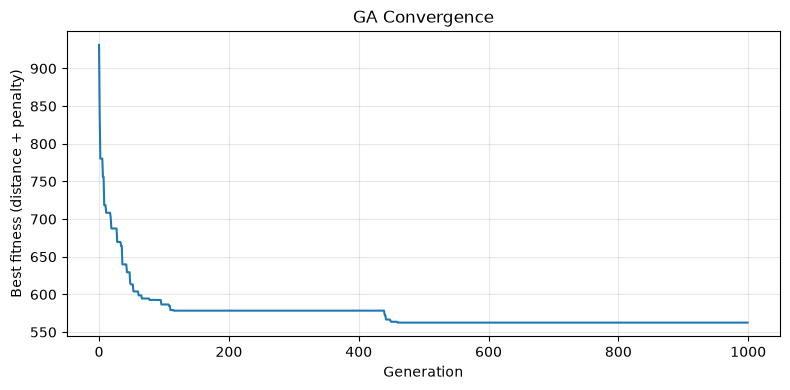

In [20]:
# ============================================
# 20. GA CONVERGENCE PLOT
# ============================================

# Best fitness per generation (before the final 2-opt step).
# Values above 1000 include the penalty for extra vehicles.

plt.figure(figsize=(8, 4))

plt.plot(ga_history)

plt.xlabel("Generation")
plt.ylabel("Best fitness (distance + penalty)")
plt.title("GA Convergence")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## GA Robustness Across Seeds

The GA is stochastic, so a single run can be lucky or unlucky. It is run with 10 different random seeds, and the best, mean and standard deviation of the total distance are reported.

In [21]:
# ============================================
# 21. GA MULTI-SEED RUNS
# ============================================

ga_runs = []

for seed in range(10):

    routes, runtime, _ = solve_ga(
        customers=customers,
        distance_matrix=distance_matrix,
        num_vehicles=NUM_VEHICLES,
        vehicle_capacity=VEHICLE_CAPACITY,
        seed=seed
    )

    valid, _ = validate_solution(
        routes,
        customers,
        NUM_VEHICLES,
        VEHICLE_CAPACITY
    )

    ga_runs.append({
        "seed": seed,
        "distance": calculate_total_distance(
            routes,
            distance_matrix
        ),
        "vehicles": len(routes),
        "runtime_s": runtime,
        "valid": valid
    })

ga_runs = pd.DataFrame(ga_runs)

print(ga_runs.round(2).to_string(index=False))

print("\nBest distance:", round(ga_runs["distance"].min(), 2))
print("Mean distance:", round(ga_runs["distance"].mean(), 2))
print("Std distance:", round(ga_runs["distance"].std(), 2))
print("Mean runtime:", round(ga_runs["runtime_s"].mean(), 2), "seconds")

 seed  distance  vehicles  runtime_s  valid
    0    531.58         4       2.74   True
    1    527.84         4       2.77   True
    2    556.38         4       2.67   True
    3    527.84         4       2.69   True
    4    519.60         4       2.59   True
    5    557.72         4       2.72   True
    6    553.49         4       2.56   True
    7    552.29         4       2.76   True
    8    557.72         4       2.78   True
    9    528.02         4       2.59   True

Best distance: 519.6
Mean distance: 541.25
Std distance: 15.42
Mean runtime: 2.69 seconds


## GA Route Map

Each vehicle route is drawn on the customer coordinates. The depot is the black square; the numbers are customer IDs. `plot_routes` works for any list of routes, so it can also be used to draw the ILP solution.

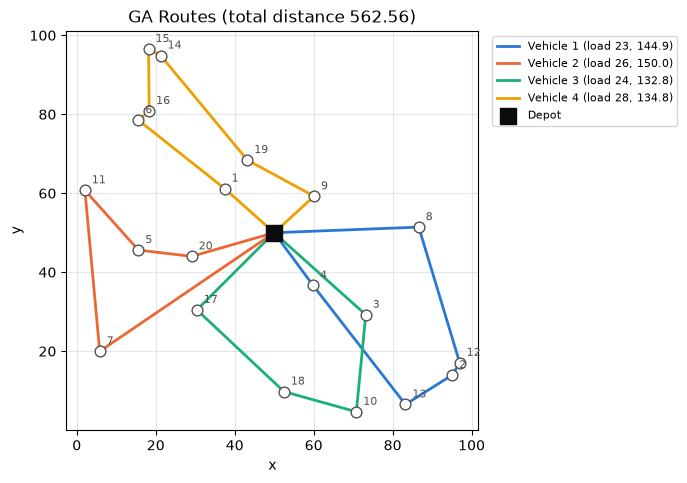

In [22]:
# ============================================
# 22. GA ROUTE MAP
# ============================================

# Fixed colour order: vehicle k always gets the same colour
ROUTE_COLORS = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100",
    "#e87ba4", "#008300", "#4a3aa7", "#e34948"
]


def plot_routes(
    routes,
    customers,
    distance_matrix,
    title,
    depot_x=50,
    depot_y=50,
    ax=None
):

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))

    xs = [depot_x] + customers["x"].tolist()
    ys = [depot_y] + customers["y"].tolist()

    for k, route in enumerate(routes):

        load = calculate_route_load(route, customers)
        distance = calculate_route_distance(route, distance_matrix)

        ax.plot(
            [xs[node] for node in route],
            [ys[node] for node in route],
            color=ROUTE_COLORS[k % len(ROUTE_COLORS)],
            linewidth=2,
            label=f"Vehicle {k + 1} (load {load}, {distance:.1f})"
        )

    # Customers
    ax.scatter(
        xs[1:], ys[1:],
        s=60, color="white",
        edgecolor="#52514e", zorder=3
    )

    for node in range(1, len(xs)):

        ax.annotate(
            str(node),
            (xs[node], ys[node]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=8,
            color="#52514e"
        )

    # Depot
    ax.scatter(
        [depot_x], [depot_y],
        s=120, marker="s", color="#0b0b0b",
        zorder=4, label="Depot"
    )

    total = calculate_total_distance(routes, distance_matrix)

    ax.set_title(f"{title} (total distance {total:.2f})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)

    return ax


plot_routes(
    ga_routes,
    customers,
    distance_matrix,
    title="GA Routes"
)

plt.tight_layout()
plt.show()

## GA Parameter Sensitivity

To justify the chosen settings, one parameter is varied at a time while the others stay at their defaults (population 150, mutation rate 0.3, 1000 generations). Each setting is run with 5 seeds, and the mean ± standard deviation of total distance is reported. This cell takes roughly 1–2 minutes.

                       best_distance  mean_distance  std_distance  mean_runtime_s
parameter       value                                                            
mutation_rate   0.1           553.49         556.69          3.82            2.61
                0.2           519.60         534.54         17.60            2.54
                0.3           519.60         532.65         13.97            2.63
                0.5           519.60         534.28         20.11            2.71
population_size 50.0          531.58         544.22          9.23            0.89
                100.0         519.60         549.53         18.65            1.81
                150.0         519.60         532.65         13.97            2.74
                200.0         519.60         537.55         13.84            3.54


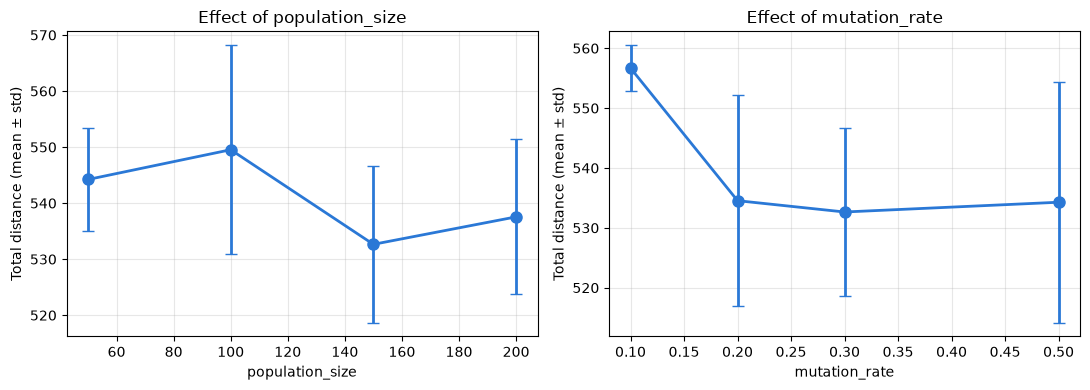

In [23]:
# ============================================
# 23. GA PARAMETER SENSITIVITY
# ============================================

SENSITIVITY_SEEDS = range(5)

parameter_grid = {
    "population_size": [50, 100, 150, 200],
    "mutation_rate": [0.1, 0.2, 0.3, 0.5]
}

sensitivity_results = []

for parameter, values in parameter_grid.items():

    for value in values:

        for seed in SENSITIVITY_SEEDS:

            routes, runtime, _ = solve_ga(
                customers=customers,
                distance_matrix=distance_matrix,
                num_vehicles=NUM_VEHICLES,
                vehicle_capacity=VEHICLE_CAPACITY,
                seed=seed,
                **{parameter: value}
            )

            sensitivity_results.append({
                "parameter": parameter,
                "value": value,
                "seed": seed,
                "distance": calculate_total_distance(
                    routes,
                    distance_matrix
                ),
                "runtime_s": runtime
            })

sensitivity_results = pd.DataFrame(sensitivity_results)

sensitivity_summary = (
    sensitivity_results
    .groupby(["parameter", "value"])
    .agg(
        best_distance=("distance", "min"),
        mean_distance=("distance", "mean"),
        std_distance=("distance", "std"),
        mean_runtime_s=("runtime_s", "mean")
    )
    .round(2)
)

print(sensitivity_summary.to_string())

# ----------------------------------------
# Plot: one panel per parameter
# ----------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, parameter in zip(axes, parameter_grid):

    summary = sensitivity_summary.loc[parameter]

    ax.errorbar(
        summary.index,
        summary["mean_distance"],
        yerr=summary["std_distance"],
        color="#2a78d6",
        linewidth=2,
        marker="o",
        markersize=8,
        capsize=4
    )

    ax.set_xlabel(parameter)
    ax.set_ylabel("Total distance (mean ± std)")
    ax.set_title(f"Effect of {parameter}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## GA Scalability

The GA is run on instances with 10 to 100 customers, generated with the same function and seed. Vehicle capacity stays at 30, and the fleet size is set to the minimum number of vehicles the total demand requires, plus one spare. The GA settings are unchanged (population 150, 1000 generations), so the computational budget is fixed. Each size is run with 3 seeds. This cell takes roughly 1–2 minutes.

           fleet_size  best_distance  mean_distance  std_distance  mean_runtime_s  all_valid
customers                                                                                   
10                  3         324.21         324.21          0.00            2.17       True
20                  5         519.60         546.18         23.23            2.61       True
30                  7         761.23         811.61         43.63            3.13       True
50                 10        1177.39        1202.36         22.22            3.77       True
75                 14        1605.32        1680.06         69.00            4.98       True
100                17        2247.88        2315.26         63.57            5.93       True


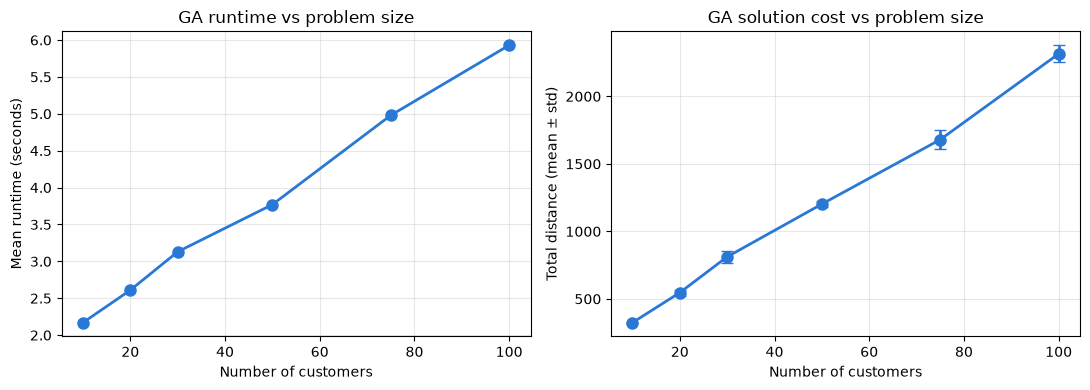

In [24]:
# ============================================
# 24. GA SCALABILITY
# ============================================

SCALABILITY_SIZES = [10, 20, 30, 50, 75, 100]
SCALABILITY_SEEDS = range(3)

scalability_results = []

for n in SCALABILITY_SIZES:

    instance = generate_dataset(n, seed=42)

    instance_matrix = calculate_distance_matrix(instance)

    # Minimum vehicles needed for total demand, plus one spare
    instance_vehicles = math.ceil(
        instance["demand"].sum() / VEHICLE_CAPACITY
    ) + 1

    for seed in SCALABILITY_SEEDS:

        routes, runtime, _ = solve_ga(
            customers=instance,
            distance_matrix=instance_matrix,
            num_vehicles=instance_vehicles,
            vehicle_capacity=VEHICLE_CAPACITY,
            seed=seed
        )

        valid, _ = validate_solution(
            routes,
            instance,
            instance_vehicles,
            VEHICLE_CAPACITY
        )

        scalability_results.append({
            "customers": n,
            "fleet_size": instance_vehicles,
            "seed": seed,
            "vehicles_used": len(routes),
            "distance": calculate_total_distance(
                routes,
                instance_matrix
            ),
            "runtime_s": runtime,
            "valid": valid
        })

scalability_results = pd.DataFrame(scalability_results)

scalability_summary = (
    scalability_results
    .groupby("customers")
    .agg(
        fleet_size=("fleet_size", "first"),
        best_distance=("distance", "min"),
        mean_distance=("distance", "mean"),
        std_distance=("distance", "std"),
        mean_runtime_s=("runtime_s", "mean"),
        all_valid=("valid", "all")
    )
    .round(2)
)

print(scalability_summary.to_string())

# ----------------------------------------
# Plot: runtime and distance as separate panels
# ----------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    scalability_summary.index,
    scalability_summary["mean_runtime_s"],
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=8
)

axes[0].set_xlabel("Number of customers")
axes[0].set_ylabel("Mean runtime (seconds)")
axes[0].set_title("GA runtime vs problem size")
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    scalability_summary.index,
    scalability_summary["mean_distance"],
    yerr=scalability_summary["std_distance"],
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=8,
    capsize=4
)

axes[1].set_xlabel("Number of customers")
axes[1].set_ylabel("Total distance (mean ± std)")
axes[1].set_title("GA solution cost vs problem size")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()